# Assignment 5

## You should:

1. read the training 

antimicrobial_train_80pct.csv

and feature-only 

antimicrobial_test_X_20pct.csv

2. exclude IDs, SMILES, and assay metadata from the predictive feature matrix;
3. detect and handle the pseudo-NA values;
4. fit and compare at least 3 dofferent tree-based models (y=target_log10);
5. generate predictions for every row in the feature-only test table - your goal is achieve 2 MAE, you can use any model we discussed(no deep learning) and any preprocessing you like;
6. submit predictions keyed by molecule_chembl_id, and just orally defend and explain your notebook.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import joblib
import json
from datetime import datetime
from pathlib import Path

RANDOM_STATE = 42


In [5]:
test_df = pd.read_csv("antimicrobial_test_X_20pct.csv")
test_df.head()


,activity_id,molecule_chembl_id,pref_name,compound_name,canonical_smiles,standard_type,standard_units,assay_chembl_id,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,...,rdkit_fr_sulfide,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiocyan,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea
0,849731,CHEMBL121649,NaN,NaN,O=C(Cc1ccccc1)N[C@@H]1C(=O)N2C(C(=O)O)=C(CCO)C...,MIC,ug.mL-1,CHEMBL673564,12.247022,12.247022,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,287078,CHEMBL68208,NaN,NaN,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)[O-])=C(CSC(=S)N...,MIC,ug.mL-1,CHEMBL676864,12.092750,12.092750,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,863129,CHEMBL134718,NaN,NaN,O=C(NC[C@H]1CN(c2ccc(N3CCS(=O)(=O)CC3)c(F)c2)C...,MIC,ug.mL-1,CHEMBL679456,14.677104,14.677104,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,736683,CHEMBL346824,NaN,NaN,O=C(NNc1ccccc1)c1ccc(NC(=S)Nc2ccc(NC(=S)Nc3ccc...,MIC,ug.mL-1,CHEMBL649395,12.406924,12.406924,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1219627,CHEMBL129494,NaN,NaN,CCCCCCCCCCCCOC(=O)c1cc(O)cc(O)c1O,MIC,ug.mL-1,CHEMBL809819,11.825847,11.825847,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0


In [6]:
train_df = pd.read_csv("antimicrobial_train_80pct.csv")
train_df.head()


,activity_id,molecule_chembl_id,pref_name,compound_name,canonical_smiles,standard_type,standard_units,assay_chembl_id,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,...,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiocyan,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea,target_log10
0,946920,CHEMBL72286,NaN,NaN,O=C(c1ccccc1O)N1CCc2c(n(Cc3ccc(O)cc3)c3ccccc23)C1,MIC,ug.mL-1,CHEMBL677573,13.081525,13.081525,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903090
1,379615,CHEMBL134905,NaN,NaN,CC(=O)NC[C@H]1CN(c2ccc3c(c2)CCCCN3C=O)C(=O)O1,MIC,ug.mL-1,CHEMBL677421,12.110715,12.110715,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
2,16571259,CHEMBL3798190,NaN,NaN,CCn1cc(C(=O)O)c(=O)c2cc(F)c(N3CCNCC3)cc21.O=[N...,MIC,ug.mL-1,CHEMBL3801691,14.494909,14.494909,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.892095
3,141787,CHEMBL320039,NaN,NaN,N[C@H]1CN(c2c(F)cc3c(=O)c(C(=O)O)cn(C4CC4)c3c2...,MIC,ug.mL-1,CHEMBL677359,15.030342,15.030342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.221849
4,551390,CHEMBL88523,NaN,NaN,O=C(OCC1=CC=C(COC(=O)c2cccnc2)SS1)c1cccnc1,MIC,ug.mL-1,CHEMBL648210,11.880338,11.880338,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030


In [7]:
excluded_columns = [
  "activity_id",
  "molecule_chembl_id",
  "pref_name",
  "compound_name",
  "canonical_smiles",
  "standard_type",
  "standard_units",
  "assay_chembl_id",
  "rdkit_NumRadicalElectrons",
  "rdkit_SMR_VSA8",
  "rdkit_fr_barbitur",
  "rdkit_fr_benzodiazepine",
  "rdkit_fr_diazo",
  "rdkit_fr_dihydropyridine",
  "rdkit_fr_isocyan",
  "rdkit_fr_isothiocyan",
  "rdkit_fr_nitroso",
  "rdkit_fr_thiocyan",
]

train = train_df.drop(columns=excluded_columns)
test = test_df.drop(columns=excluded_columns)

train.head()


,rdkit_MaxAbsEStateIndex,rdkit_MaxEStateIndex,rdkit_MinAbsEStateIndex,rdkit_MinEStateIndex,rdkit_qed,rdkit_SPS,rdkit_MolWt,rdkit_HeavyAtomMolWt,rdkit_ExactMolWt,rdkit_NumValenceElectrons,...,rdkit_fr_sulfide,rdkit_fr_sulfonamd,rdkit_fr_sulfone,rdkit_fr_term_acetylene,rdkit_fr_tetrazole,rdkit_fr_thiazole,rdkit_fr_thiophene,rdkit_fr_unbrch_alkane,rdkit_fr_urea,target_log10
0,13.081525,13.081525,0.011976,-0.152602,0.540794,13.400000,398.462,376.286,398.163043,150.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903090
1,12.110715,12.110715,0.149552,-0.410956,0.847072,20.208333,331.372,310.204,331.153206,128.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030
2,14.494909,14.494909,0.100124,-1.300287,0.169941,13.195122,595.884,576.732,595.086596,216.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.892095
3,15.030342,15.030342,0.011741,-1.321205,0.839431,23.370370,391.830,372.678,391.109897,142.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.221849
4,11.880338,11.880338,0.185165,-0.412243,0.549826,13.384615,386.454,372.342,386.039499,132.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.301030


In [8]:
def impute(data, imputer=None):
  imputer = imputer or IterativeImputer(random_state=RANDOM_STATE)
  imputed = imputer.fit_transform(data)
  return pd.DataFrame(imputed, columns=data.columns, index=data.index)


In [85]:
def fit(model, X, y, params={}):
  run_dir = Path("runs") / datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
  run_dir.mkdir(parents=True, exist_ok=True)

  cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

  search = GridSearchCV(
    model,
    params,
    cv=cv,
    scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"},
    n_jobs=-1,
    refit="rmse",
  )
  search.fit(X, y)

  best = search.best_index_
  mae = -search.cv_results_["mean_test_mae"][best]
  rmse = -search.cv_results_["mean_test_rmse"][best]

  print(search.best_params_)
  print(f"Best MAE: {mae:.4f}, RMSE: {rmse:.4f}")

  best_model = search.best_estimator_
  joblib.dump(best_model, run_dir / "model.joblib")

  metrics = {
    "mae": float(mae),
    "rmse": float(rmse),
    "best_params": search.best_params_,
  }

  with open(run_dir / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=str)

  return best_model, mae, rmse

def load(run_dir):
  return joblib.load(run_dir / "model.joblib")


In [69]:
TARGET = "target_log10"
y = train[TARGET]
X = train[train.columns[~train.columns.isin([TARGET])]]

def x_stats(X):
  num = X.select_dtypes("number")

  stats = pd.DataFrame({
    "mean": num.mean(),
    "var": num.var(),
    "n_na": X.isna().sum(),
    "pct_na": X.isna().mean(),
  })
  stats.sort_values("n_na", ascending=False)

  fig = px.scatter(
    stats.reset_index(names="feature"),
    x="mean", y="var",
    color="pct_na",
    hover_name="feature",
    hover_data={"n_na": True, "pct_na": ":.2f"},
    log_y=True,
    labels={"mean": "Mean", "var": "Variance", "pct_na": "% NA"},
    title="Mean vs variance per feature",
  ) 
  fig.show()

  return stats



In [70]:
x_stats(X)


,mean,var,n_na,pct_na
rdkit_MaxAbsEStateIndex,12.606079,7.665852,168,0.019823
rdkit_MaxEStateIndex,12.594982,7.693548,179,0.021121
rdkit_MinAbsEStateIndex,0.120967,0.026349,193,0.022773
rdkit_MinEStateIndex,-1.311952,1.414970,147,0.017345
rdkit_qed,0.467145,0.075793,180,0.021239
...,...,...,...,...
rdkit_fr_tetrazole,0.014685,0.014471,167,0.019705
rdkit_fr_thiazole,0.110295,0.216398,170,0.020059
rdkit_fr_thiophene,0.034504,0.034041,186,0.021947
rdkit_fr_unbrch_alkane,0.551857,5.083187,183,0.021593


In [71]:
display(X["rdkit_Ipc"].describe())
X["rdkit_Ipc"] = np.log10(X["rdkit_Ipc"] + 1)

x_stats(X)


count    8.320000e+03
mean     2.376868e+81
std      2.168037e+83
min      9.651484e+00
25%      1.861941e+05
50%      2.656450e+06
75%      4.052446e+08
max      1.977554e+85
Name: rdkit_Ipc, dtype: float64

,mean,var,n_na,pct_na
rdkit_MaxAbsEStateIndex,12.606079,7.665852,168,0.019823
rdkit_MaxEStateIndex,12.594982,7.693548,179,0.021121
rdkit_MinAbsEStateIndex,0.120967,0.026349,193,0.022773
rdkit_MinEStateIndex,-1.311952,1.414970,147,0.017345
rdkit_qed,0.467145,0.075793,180,0.021239
...,...,...,...,...
rdkit_fr_tetrazole,0.014685,0.014471,167,0.019705
rdkit_fr_thiazole,0.110295,0.216398,170,0.020059
rdkit_fr_thiophene,0.034504,0.034041,186,0.021947
rdkit_fr_unbrch_alkane,0.551857,5.083187,183,0.021593


In [72]:
X = impute(X)
x_stats(X)


,mean,var,n_na,pct_na
rdkit_MaxAbsEStateIndex,12.599492,7.665274,0,0.0
rdkit_MaxEStateIndex,12.599492,7.665274,0,0.0
rdkit_MinAbsEStateIndex,0.120540,0.026141,0,0.0
rdkit_MinEStateIndex,-1.309795,1.410724,0,0.0
rdkit_qed,0.467864,0.075377,0,0.0
...,...,...,...,...
rdkit_fr_tetrazole,0.014464,0.014253,0,0.0
rdkit_fr_thiazole,0.111512,0.221409,0,0.0
rdkit_fr_thiophene,0.034154,0.033526,0,0.0
rdkit_fr_unbrch_alkane,0.554969,5.150400,0,0.0


In [73]:
px.histogram(
  y,
  nbins=50,
  marginal="box",
)


In [80]:
X_scaled = StandardScaler().fit_transform(X)

tsne = TSNE(
  n_components=2, perplexity=30, init="pca",
  learning_rate="auto", random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_scaled)
tsne_df = pd.DataFrame(X_tsne, columns=["tSNE1", "tSNE2"], index=X.index).join(y)


In [81]:
fig = px.scatter(
  tsne_df.reset_index(), x="tSNE1", y="tSNE2", color=TARGET,
  hover_name=tsne_df.index.name or "index",
  opacity=0.5,
  title=f"t-SNE colored by {TARGET}",
  width=600, height=500,
)
fig.update_traces(marker_size=4)
fig.show()


In [97]:
tree = DecisionTreeRegressor()

best_tree, tree_mae, tree_rmse = fit(tree, X, y, params = {
  "max_depth": [3, 5, 8, 12, 16, 24, None],
  "min_samples_split": [2, 5, 10, 20, 50],
  "min_samples_leaf": [1, 2, 5, 10, 20, 50],
})


{'max_depth': 16, 'min_samples_leaf': 20, 'min_samples_split': 10}
Best MAE: 0.6903, RMSE: 0.9324


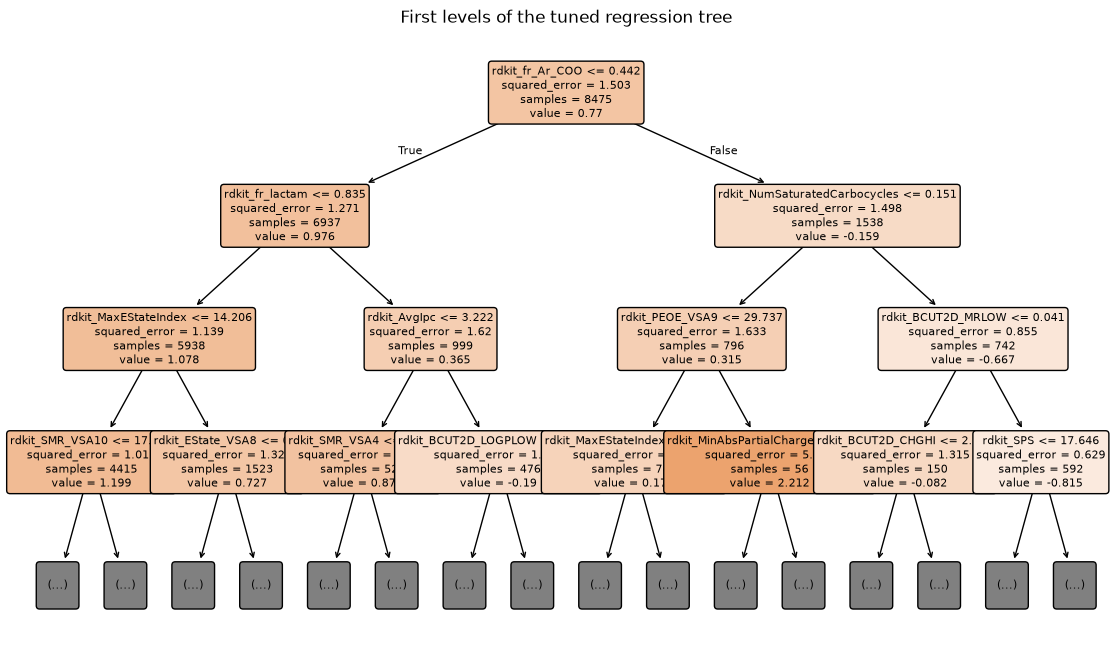

In [98]:
plt.figure(figsize=(14, 8))
plot_tree(
  best_tree,
  max_depth=3,
  feature_names=list(X.columns),
  filled=True,
  rounded=True,
  fontsize=8,
)
plt.title("First levels of the tuned regression tree")
plt.show()


In [99]:
rf = RandomForestRegressor(
  bootstrap=True,
  oob_score=True,
  random_state=RANDOM_STATE,
)

best_rf, rf_mae, rf_rmse = fit(rf, X, y, params={
  "n_estimators": [300],
  "max_features": ["sqrt", 0.3, 0.5],
  "max_depth": [16, 32, None],
  "min_samples_leaf": [1, 3, 5],
  "max_samples": [0.7, None],
})


{'max_depth': 32, 'max_features': 0.5, 'max_samples': None, 'min_samples_leaf': 1, 'n_estimators': 300}
Best MAE: 0.5427, RMSE: 0.7453


In [100]:
xgb = XGBRegressor(
  n_estimators=300, learning_rate=0.05, max_depth=4,
  min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
  reg_lambda=1.0, objective="reg:squarederror",
  random_state=RANDOM_STATE)

best_xgb, xgb_mae, xgb_rmse = fit(xgb, X, y, params={
  "learning_rate": [0.03, 0.1],
  "max_depth": [4, 6, 8],
  "min_child_weight": [1, 5],
  "subsample": [0.8],
  "colsample_bytree": [0.5, 0.8],
})


{'colsample_bytree': 0.5, 'learning_rate': 0.1, 'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.8}
Best MAE: 0.5334, RMSE: 0.7393


In [101]:
results = pd.DataFrame({
  "Decision tree": {"MAE": tree_mae, "RMSE": tree_rmse},
  "Random forest": {"MAE": rf_mae,   "RMSE": rf_rmse},
  "XGBoost":       {"MAE": xgb_mae,  "RMSE": xgb_rmse},
}).T.rename_axis("model").reset_index()

baseline_mae = (y - y.median()).abs().mean()

fig = px.bar(
  results.melt(id_vars="model", var_name="metric", value_name="score"),
  x="model", y="score", color="metric", barmode="group",
  text_auto=".3f",
  title="Cross-validated error by model (lower is better)",
  labels={"score": "error (log10 MIC units)", "model": ""},
)

fig.add_hline(
  y=baseline_mae,
  line_dash="dash",
  annotation_text=f"median baseline MAE = {baseline_mae:.2f}"
)

fig.update_layout(width=750, height=450)
fig.show()

results.sort_values("MAE")


,model,MAE,RMSE
2,XGBoost,0.533398,0.739318
1,Random forest,0.542701,0.745348
0,Decision tree,0.690257,0.932405


In [102]:
best_model = best_xgb

X_test = test[X.columns].copy()
X_test["rdkit_Ipc"] = np.log10(test["rdkit_Ipc"] + 1)
X_test = impute(X_test)

pred = best_model.predict(X_test)

submission = pd.DataFrame({
  "molecule_chembl_id": test_df["molecule_chembl_id"],
  TARGET: pred,
})

out_path = Path("output/predictions_xgb.csv")
out_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(out_path, index=False)
submission.head()


,molecule_chembl_id,target_log10
0,CHEMBL121649,0.345100
1,CHEMBL68208,0.717989
2,CHEMBL134718,0.251387
3,CHEMBL346824,1.126213
4,CHEMBL129494,2.041244
